[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/rglopesdf/mineracao-textos-2026/blob/main/notebooks/01_do_texto_ao_vetor.ipynb)

# Notebook 01 · Do texto ao vetor
**Mineração de Textos · Encontros 02 (17/11) e 03 (18/11) · Projeto Voz do Cliente, Etapa 1**

Neste notebook vamos sair de 132 mil avaliações reais de clientes da Americanas.com e chegar a vetores que um modelo consegue usar. Cada bloco segue o mesmo roteiro da aula: **problema → conceito → solução**.

| Bloco | Problema | Conceito | Solução |
|---|---|---|---|
| 1 | O texto vem sujo | Pré-processamento | Um pipeline com decisões justificadas |
| 2 | Contar palavras engana | BoW e TF-IDF | Termos que distinguem notas 1 e 5 |
| 3 | Mesmo problema, palavras diferentes | Embeddings e similaridade | Busca semântica e mapa 2D |

No fim, a seção **Etapa 1** traz o que o grupo precisa entregar.

> Dataset: B2W-Reviews01 (Real, Oshiro e Mafra, STIL 2019), licença CC BY-NC-SA 4.0. Uso acadêmico com crédito à B2W Digital.

## 0. Preparação do ambiente
No Colab, rode esta célula uma vez. Ela instala o que falta e baixa o modelo de português do spaCy.

#### Entendendo o código

Esta célula prepara o ambiente. Só precisa rodar uma vez por sessão do Colab.

- `importlib.util.find_spec("umap")` verifica se um pacote já está instalado **sem importá-lo**. Devolve `None` quando ele não existe.
- `[p for p, m in [...] if ...]` é uma **compreensão de lista** (*list comprehension*): uma forma compacta de montar uma lista percorrendo outra e filtrando itens. Aqui ela guarda só os pacotes que faltam.
- `subprocess.run([sys.executable, "-m", "pip", "install", "-q", *faltando])` chama o `pip` do mesmo Python do notebook. Equivale a `!pip install -q ...` no Colab. O `*` desempacota a lista: cada pacote vira um argumento.
- **spaCy** é uma biblioteca de processamento de linguagem natural. `spacy.load("pt_core_news_sm")` carrega o modelo pequeno de **português**, que sabe separar palavras, identificar a classe gramatical e encontrar o lema de cada palavra.
- `disable=["parser", "ner"]` desliga a análise sintática e o reconhecimento de entidades (nomes, lugares). Não vamos usá-los, e o processamento fica bem mais rápido.
- `try` / `except OSError`: se o modelo ainda não foi baixado, o `load` dá erro; nesse caso baixamos (`spacy.cli.download`) e carregamos de novo.
- `nltk.download("stopwords")` baixa as listas de *stopwords* do NLTK, que usaremos no Bloco 1.

In [2]:
import importlib.util, subprocess, sys
faltando = [p for p, m in [("sentence-transformers", "sentence_transformers"), ("umap-learn", "umap")] if importlib.util.find_spec(m) is None]
if faltando:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *faltando], check=True)
import spacy
try:
    nlp = spacy.load("pt_core_news_sm", disable=["parser", "ner"])
except OSError:
    spacy.cli.download("pt_core_news_sm")
    nlp = spacy.load("pt_core_news_sm", disable=["parser", "ner"])
import nltk
nltk.download("stopwords", quiet=True)
print("Ambiente pronto")

✔ Download and installation successful
You can now load the package via spacy.load('pt_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
Ambiente pronto


#### Entendendo o código

Importações e configurações usadas no notebook inteiro.

| Biblioteca | Para quê |
|---|---|
| `os` | acessar variáveis de ambiente e arquivos |
| `re` | **expressões regulares**, para buscar padrões em texto |
| `collections` | estruturas úteis, como o `Counter` (contador) |
| `numpy` (`np`) | vetores e matrizes numéricas |
| `pandas` (`pd`) | tabelas (*DataFrames*) |
| `matplotlib.pyplot` (`plt`) | gráficos |

- `pd.set_option("display.max_colwidth", 140)` mostra até 140 caracteres de cada texto quando uma tabela é exibida (o padrão corta em 50).
- `plt.rcParams.update({...})` define o tamanho padrão das figuras e remove as bordas de cima e da direita dos gráficos.

In [3]:
import os, re, collections
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 140)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False})

## 1. Carregar e conhecer os dados
O CSV tem cerca de 50 MB e é lido direto do GitHub.

#### Entendendo o código

Leitura do dataset.

- `os.environ.get("B2W_CSV", URL)` procura uma variável de ambiente chamada `B2W_CSV`; se ela não existir, usa o link do GitHub. Assim quem tem o arquivo no computador pode apontar para a cópia local sem mudar o código. No Colab, vale o link.
- `pd.read_csv(URL, low_memory=False)` lê o CSV direto da internet e devolve um **DataFrame**, a tabela do pandas. `low_memory=False` faz o pandas olhar o arquivo inteiro antes de decidir o tipo de cada coluna, evitando avisos de tipos misturados.
- `df_full.shape` devolve `(linhas, colunas)`.
- `df_full.head(3)` mostra as 3 primeiras linhas. Como é a última linha da célula, o Jupyter exibe o resultado como tabela.

Colunas que usaremos mais: `review_text` (o texto da avaliação), `overall_rating` (nota de 1 a 5), `recommend_to_a_friend` (Yes/No) e `site_category_lv1` (categoria do produto).

In [4]:
URL = os.environ.get("B2W_CSV", "https://raw.githubusercontent.com/americanas-tech/b2w-reviews01/main/B2W-Reviews01.csv")
df_full = pd.read_csv(URL, low_memory=False)
print(df_full.shape)
df_full.head(3)

(132373, 14)


,submission_date,reviewer_id,product_id,product_name,product_brand,site_category_lv1,site_category_lv2,review_title,overall_rating,recommend_to_a_friend,review_text,reviewer_birth_year,reviewer_gender,reviewer_state
0,2018-01-01 00:11:28,d0fb1ca69422530334178f5c8624aa7a99da47907c44de0243719b15d50623ce,132532965,"Notebook Asus Vivobook Max X541NA-GO472T Intel Celeron Quad Core 4GB 500GB Tela LED 15,6"" Windows - 10 Branco",NaN,Informática,Notebook,Bom,4,Yes,Estou contente com a compra entrega rápida o único problema com as Americanas é se houver troca ou devolução do produto o consumidor tem...,1958.0,F,RJ
1,2018-01-01 00:13:48,014d6dc5a10aed1ff1e6f349fb2b059a2d3de511c7538a9008da562ead5f5ecd,22562178,Copo Acrílico Com Canudo 500ml Rocie,NaN,Utilidades Domésticas,"Copos, Taças e Canecas","Preço imbatível, ótima qualidade",4,Yes,"Por apenas R$1994.20,eu consegui comprar esse lindo copo de acrílico.",1996.0,M,SC
2,2018-01-01 00:26:02,44f2c8edd93471926fff601274b8b2b5c4824e386ae4f210329b9b71890277fd,113022329,Panela de Pressão Elétrica Philips Walita Daily 5L com Timer,philips walita,Eletroportáteis,Panela Elétrica,ATENDE TODAS AS EXPECTATIVA.,4,Yes,"SUPERA EM AGILIDADE E PRATICIDADE OUTRAS PANELAS ELÉTRICAS. COSTUMO USAR OUTRA PANELA PARA COZIMENTO DE ARROZ (JAPONESA), MAS LEVA MUIT...",1984.0,M,SP


Removemos textos vazios e duplicados e trabalhamos com uma **amostra de 20 mil avaliações** para tudo rodar rápido no Colab. A semente fixa (`random_state=42`) garante que todos vejam a mesma amostra.

#### Entendendo o código

Limpeza mínima e amostragem.

- `df_full["review_text"].notna()` devolve uma coluna de `True`/`False`: `True` onde o texto não é nulo. Isso se chama **máscara booleana**. Usada entre colchetes, `df_full[mascara]`, ela mantém só as linhas `True`.
- `.str.strip() != ""` descarta textos que só têm espaços. O **acessor `.str`** aplica uma operação de texto à coluna inteira de uma vez.
- `&` combina duas máscaras (as duas condições precisam ser verdadeiras).
- `drop_duplicates("review_text")` mantém só a primeira ocorrência de cada texto idêntico. Textos repetidos distorcem contagens e, mais adiante, contaminam a separação entre treino e teste.
- `df.sample(20_000, random_state=42)` sorteia 20 mil linhas. O `random_state` é a **semente**: com o mesmo valor, todos obtêm exatamente a mesma amostra. O `_` em `20_000` só facilita a leitura.
- `reset_index(drop=True)` renumera as linhas de 0 a 19.999.
- `.str.split().str.len()` quebra cada texto nos espaços e conta os pedaços: uma estimativa do número de palavras.
- `value_counts().sort_index()` conta quantas avaliações há de cada nota e ordena pela nota.

In [5]:
df = df_full[df_full["review_text"].notna() & (df_full["review_text"].str.strip() != "")]
print("vazios removidos:", len(df_full) - len(df))
df = df.drop_duplicates("review_text")
print("depois de remover duplicados:", len(df))
amostra = df.sample(20_000, random_state=42).reset_index(drop=True)
amostra["n_palavras"] = amostra["review_text"].str.split().str.len()
amostra["overall_rating"].value_counts().sort_index()

vazios removidos: 3275
depois de remover duplicados: 126724


,count
overall_rating,
1,3912
2,1280
3,2473
4,5021
5,7314


#### Entendendo o código

Dois gráficos para conhecer a amostra.

- `plt.subplots(1, 2, figsize=(12, 4))` cria uma figura com **1 linha e 2 colunas** de gráficos. `ax[0]` e `ax[1]` são as duas áreas de desenho.
- O pandas desenha direto: `.plot.bar(ax=ax[0])` (barras) e `.plot.hist(bins=40, ax=ax[1])` (histograma com 40 faixas).
- `.clip(upper=120)` troca qualquer valor acima de 120 por 120. Algumas avaliações são enormes; sem o corte, elas esticariam o eixo e o histograma ficaria espremido.
- `plt.tight_layout()` ajusta os espaços entre os gráficos; `plt.show()` exibe.
- `.describe()` resume a coluna: contagem, média, desvio padrão, mínimo, quartis e máximo.

**O que observar:** as notas não estão equilibradas, e a maioria das avaliações é curta. As duas coisas influenciam todas as escolhas seguintes.

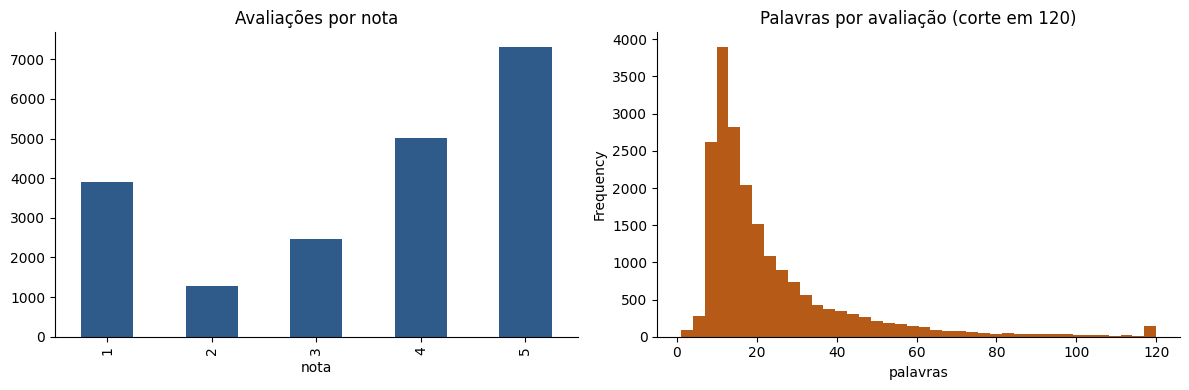

,n_palavras
count,20000.00000
mean,22.99535
std,22.08649
min,1.00000
25%,11.00000
50%,16.00000
75%,27.00000
max,696.00000


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
amostra["overall_rating"].value_counts().sort_index().plot.bar(ax=ax[0], color="#2F5B8A")
ax[0].set_title("Avaliações por nota"); ax[0].set_xlabel("nota")
amostra["n_palavras"].clip(upper=120).plot.hist(bins=40, ax=ax[1], color="#B55A17")
ax[1].set_title("Palavras por avaliação (corte em 120)"); ax[1].set_xlabel("palavras")
plt.tight_layout(); plt.show()
amostra["n_palavras"].describe()

## Bloco 1 · O texto vem sujo

### Problema
Antes de qualquer técnica, **leia** os textos. Rode a célula abaixo algumas vezes e anote o que aparece.

#### Entendendo o código

Ler antes de modelar.

- `amostra.sample(8)` sorteia 8 avaliações. Desta vez **sem semente**, de propósito: a cada execução aparecem outras.
- `itertuples()` percorre a tabela linha a linha; cada linha vira um objeto em que as colunas são atributos (`r.overall_rating`, `r.review_text`).
- `f"{r.overall_rating}★ | ..."` é uma **f-string**: o que está entre chaves é calculado e inserido no texto.
- `r.review_text[:200]` é um **fatiamento** (*slicing*): pega os 200 primeiros caracteres.

In [7]:
for r in amostra.sample(8).itertuples():
    print(f"{r.overall_rating}★ | {r.review_text[:200]}")

1★ | Como avaliar bem um produto que não é entregue com os acessórios que fazem parte para o bom uso do mesmo como o cabo para carregar a bateria?
1★ | Depois de um mês efetuada a compra, ainda não recebi o produto e cada comunicação feita com vcs, recebo as desculpas mais idiotas possíveis. NUNCA MAIS comprarei nas Lojas Americanas e ainda farei um 
5★ | Adorei o acabamento matelado, combina com qualquer ambiente.
4★ | Como sempre, é muito tranquilo comprar nessa firma.
3★ | Um celular com um custo benefício apreciável, chegou tudo certo e dentro do prazo estabelecido
1★ | Produto porcaria. As tabuas vieram com vários defeitos visuais. O gancho para pendurar que veio é completamente diferente e bem pior do que o da foto. Os parafusos que vieram foram parafusos para porc
5★ | Celular rápido, com bastante espaço em memória, nada a reclamar. Me atendeu perfeitamente.
4★ | Comprei logo 3 pra não correr o risco de perdera chance de ter um copo por esta bagatela.  Deito na minha cama banhad

Alguns padrões podem ser contados com expressões regulares:

#### Entendendo o código

Contar padrões de "sujeira" com **expressões regulares** (regex): uma mini-linguagem para descrever padrões de texto.

- `[!?]{3,}`: `!` ou `?` repetidos 3 ou mais vezes (`???`, `!!!!`).
- `\b(?:vc|q|pq|tb|td|msm)\b`: uma das palavras da lista, inteira (`vc`, mas não `vcs`).
- `([a-z])\1{3,}`: uma letra seguida dela mesma 3 ou mais vezes (`ruimmmm`).
- `https?://|www\.`: `http://`, `https://` ou `www.` (links).

- `\b` é a fronteira de palavra; `|` significa "ou"; `(?:...)` agrupa sem guardar; `\1` repete o que o primeiro grupo `(...)` encontrou; `\.` é um ponto literal (sem a barra, o ponto significa "qualquer caractere").
- O `r` antes das aspas (`r"..."`) cria uma *raw string*: as barras invertidas chegam intactas ao regex.
- `str.isupper()` é `True` quando o texto inteiro está em maiúsculas. `str.contains(padrao, case=False)` é `True` quando o padrão aparece, ignorando maiúsculas e minúsculas.
- `{k: int(v.sum()) for k, v in sinais.items()}` é uma **compreensão de dicionário**. Somar `True`/`False` conta quantos `True` existem, porque `True` vale 1.

In [8]:
sinais = {
    "CAIXA ALTA": amostra["review_text"].str.isupper(),
    "pontuação repetida (!!!, ???)": amostra["review_text"].str.contains(r"[!?]{3,}"),
    "abreviações (vc, q, pq, tb, msm)": amostra["review_text"].str.contains(r"\b(?:vc|q|pq|tb|td|msm)\b", case=False),
    "letras esticadas (ruimmmm)": amostra["review_text"].str.contains(r"([a-z])\1{3,}", case=False),
    "URL": amostra["review_text"].str.contains(r"https?://|www\.", case=False),
}
pd.Series({k: int(v.sum()) for k, v in sinais.items()}, name="avaliações").to_frame()

/tmp/ipykernel_423/2337782919.py:5: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "letras esticadas (ruimmmm)": amostra["review_text"].str.contains(r"([a-z])\1{3,}", case=False),


,avaliações
CAIXA ALTA,572
"pontuação repetida (!!!, ???)",989
"abreviações (vc, q, pq, tb, msm)",699
letras esticadas (ruimmmm),226
URL,17


### A armadilha do "não"
A lista de stopwords do NLTK é o ponto de partida mais comum. Veja o que ela faz com uma reclamação:

#### Entendendo o código

**Stopwords** são palavras muito frequentes e, em geral, pouco informativas (artigos, preposições, pronomes). Removê-las reduz o vocabulário. O risco é a lista conter palavras que importam para o **seu** problema.

- `stopwords.words("portuguese")` devolve a lista do NLTK (cerca de 200 palavras). Convertemos em `set` (conjunto) porque testar `palavra in conjunto` é instantâneo, mesmo com listas grandes.
- `"não" in stop_nltk` testa se a palavra está na lista.
- A compreensão de lista `[w for w in frase.lower().split() if w not in stop_nltk]` mantém só as palavras que **não** estão na lista. Observe o que sobra da frase.

In [9]:
from nltk.corpus import stopwords
stop_nltk = set(stopwords.words("portuguese"))
print("'não' está na lista?", "não" in stop_nltk, "| 'nao' está?", "nao" in stop_nltk)
frase = "O produto não chegou e não recebi resposta"
print([w for w in frase.lower().split() if w not in stop_nltk])

'não' está na lista? True | 'nao' está? False
['produto', 'chegou', 'recebi', 'resposta']


O efeito numa busca é imediato. Com a lista padrão, a consulta *o produto não chegou* vira só `produto chegou`:

#### Entendendo o código

O efeito da lista padrão numa busca. Esta célula antecipa ferramentas que serão explicadas no Bloco 2; aqui, o importante é o resultado.

- `TfidfVectorizer(stop_words=...)` transforma textos em números: separa as palavras, remove as stopwords informadas, monta o vocabulário e calcula um peso para cada palavra em cada texto.
- `fit_transform(textos)` faz duas coisas: **fit** (aprende o vocabulário com os textos) e **transform** (converte cada texto num vetor). O resultado é uma **matriz esparsa**: uma linha por avaliação, uma coluna por palavra, quase tudo zero.
- `v_padrao.build_analyzer()` devolve a função de pré-processamento que o vetorizador usa. Aplicada à consulta, mostra o que sobra dela.
- `v_padrao.transform([consulta])` converte a consulta usando o vocabulário **já aprendido** (sem `fit`: a consulta não altera o vocabulário).
- `cosine_similarity(consulta, X)` mede o quanto a consulta se parece com cada avaliação, de 0 (nada em comum) a 1 (mesma direção). `.ravel()` transforma o resultado num vetor simples.
- `np.argsort(-sc)[:6]` devolve as **posições** dos 6 maiores scores. `argsort` ordena do menor para o maior; o sinal de menos inverte a ordem.
- `pd.DataFrame([{...}, {...}])` monta uma tabela a partir de uma lista de dicionários: cada dicionário vira uma linha.

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
v_padrao = TfidfVectorizer(stop_words=list(stop_nltk))
X_padrao = v_padrao.fit_transform(amostra["review_text"])
print("a consulta vira:", v_padrao.build_analyzer()("o produto não chegou"))
sc = cosine_similarity(v_padrao.transform(["o produto não chegou"]), X_padrao).ravel()
pd.DataFrame([{"score": round(sc[i], 2), "nota": amostra.overall_rating[i], "texto": amostra.review_text[i][:100]} for i in np.argsort(-sc)[:6]])

a consulta vira: ['produto', 'chegou']


,score,nota,texto
0,1.00,4,este produto chegou....................................................
1,0.85,1,"ATÉ AGORA, NÃO CHEGOU.NÃO CHEGOU.NÃO CHEGOU. NÃO CHEGOU.NÃO CHEGOU.NÃO CHEGOU."
2,0.69,1,O PRODUTO AINDA NÃO CHEGOU!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
3,0.66,4,"Produto Chegou no prazo, recomendo.sem mais .....,................"
4,0.66,4,"Chegou no prazo, bom produto.,.......,.................,"
5,0.66,4,produto chegou no prazo e muito bom! recomendo o produto.


A frase perdeu as duas negações e passou a dizer o contrário. E como muitos clientes escrevem *nao* sem acento, a mesma palavra ainda vira dois tokens. **Pré-processar é decidir.**

### Conceito: as quatro decisões
1. **Tokenização:** onde cortar o texto.
2. **Normalização:** minúsculas, acentos, pontuação repetida, URLs.
3. **Stopwords:** quais palavras saem (e quais precisam ficar).
4. **Lematização:** juntar flexões (*entregue, entregaram → entregar*).

### Solução: um pipeline com decisões explícitas

#### Entendendo o código

O pipeline de pré-processamento do curso, com as quatro decisões explícitas.

- `STOP = (stop_nltk | {"produto", "americanas"}) - {"não", "nao", "nem", "sem", "mas"}` usa **operações de conjuntos**: `|` é união e `-` é diferença. Acrescentamos duas palavras que aparecem em quase todas as avaliações e devolvemos as negações e o "mas".
- `def normalizar(texto):` define uma **função**: um bloco de código com nome, que recebe uma entrada e devolve (`return`) um resultado.
- `re.sub(padrao, substituto, texto)` troca tudo o que casa com o padrão. Em `r"([a-zà-ú])\1{2,}"` → `r"\1"`, uma letra repetida 3 ou mais vezes vira uma só (`ruimmmm` → `ruim`); a faixa `à-ú` inclui as letras acentuadas.
- `nlp.pipe(...)` processa muitos textos com o spaCy **em lotes** (`batch_size=500`), bem mais rápido do que chamar `nlp(texto)` um por um.
- `(normalizar(t) for t in textos)` é uma **expressão geradora**: parecida com a compreensão de lista, mas produz um item por vez, sem guardar a lista inteira na memória.
- Para cada `tok` (token) do documento: `tok.is_alpha` é `True` só para palavras (descarta números e pontuação); `tok.lemma_` é o **lema**, a forma de dicionário (`comprei` → `comprar`, `entregue` → `entregar`).
- O `.split()` depois do lema existe porque o spaCy expande contrações: `dos` vira `de o`. Separando as partes, cada uma passa pelo filtro de stopwords.
- `lematizar=True` é um **parâmetro com valor padrão**: se ninguém informar, vale `True`.
- `" ".join(lista)` junta as palavras de volta numa única string, separadas por espaço.
- `.loc[mascara]` seleciona linhas por condição; `.iloc[0, :]` pega a primeira delas pela posição.

In [11]:
import unicodedata

STOP = (stop_nltk | {"produto", "americanas"}) - {"não", "nao", "nem", "sem", "mas"}

def normalizar(texto):
    t = texto.lower()
    t = re.sub(r"https?://\S+|www\.\S+", " ", t)      # URLs
    t = re.sub(r"([a-zà-ú])\1{2,}", r"\1", t)          # ruimmmm -> ruim
    t = re.sub(r"\bnao\b", "não", t)                   # unifica a negação
    t = re.sub(r"\b(vc)\b", "você", t)
    t = re.sub(r"\b(q)\b", "que", t)
    t = re.sub(r"\b(pq)\b", "porque", t)
    return t

def preprocessar(textos, lematizar=True):
    saida = []
    for doc in nlp.pipe((normalizar(t) for t in textos), batch_size=500):
        toks = []
        for tok in doc:
            if tok.is_alpha:
                # o spaCy expande contrações ("dos" -> "de o"): separamos as partes
                toks.extend((tok.lemma_ if lematizar else tok.text).split())
        saida.append(" ".join(w for w in toks if w not in STOP))
    return saida

exemplo = amostra.loc[amostra["review_text"].str.contains("nao", case=False)].iloc[0, :]["review_text"]
print("ORIGINAL :", exemplo)
print("NORMAL.  :", normalizar(exemplo))
print("PIPELINE :", preprocessar([exemplo])[0])

ORIGINAL : A camada externa da capa do Samsung tab S3 descolou da parte plastica com menos de uma semana de uso. Produto muito inferior a outros chineses que ja havia comprado e como ja estava usando o vendedor nao quis efetuar a troca.
NORMAL.  : a camada externa da capa do samsung tab s3 descolou da parte plastica com menos de uma semana de uso. produto muito inferior a outros chineses que ja havia comprado e como ja estava usando o vendedor não quis efetuar a troca.
PIPELINE : camada externo capa samsung tab descolar parte plastico pouco semana uso inferior outro chinês ja comprar ja usar vendedor não querer efetuar troca


Agora aplicamos o pipeline à amostra (leva cerca de um minuto) e medimos o vocabulário a cada etapa.

#### Entendendo o código

Aplicar o pipeline à amostra inteira e medir o vocabulário em cada etapa.

- `%%time` é um **comando mágico** do Jupyter: mede quanto tempo a célula leva. Precisa ser a primeira linha da célula.
- `amostra["texto_limpo"] = ...` cria uma coluna nova com o resultado do pipeline.
- `{w for t in textos for w in t.split()}` é uma **compreensão de conjunto** com dois `for` aninhados: percorre cada texto e, dentro dele, cada palavra. Como conjuntos não têm repetição, `len(...)` dá o número de palavras **distintas**, ou seja, o tamanho do vocabulário.
- `.to_frame()` converte o resultado (uma *Series*) em tabela, só para a exibição ficar mais legível.

In [12]:
%%time
amostra["texto_limpo"] = preprocessar(amostra["review_text"].tolist())

def tamanho_vocab(textos):
    return len({w for t in textos for w in t.split()})

etapas = {
    "bruto (split)": amostra["review_text"].tolist(),
    "minúsculas": amostra["review_text"].str.lower().tolist(),
    "normalizado": [normalizar(t) for t in amostra["review_text"]],
    "pipeline completo": amostra["texto_limpo"].tolist(),
}
pd.Series({k: tamanho_vocab(v) for k, v in etapas.items()}, name="palavras distintas").to_frame()

CPU times: user 48 s, sys: 332 ms, total: 48.3 s
Wall time: 1min 17s


,palavras distintas
bruto (split),42978
minúsculas,36795
normalizado,36562
pipeline completo,14314


### Lei de Zipf
Poucas palavras aparecem muito; a maioria aparece pouquíssimo. Em escala log-log a curva vira quase uma reta.

#### Entendendo o código

A **Lei de Zipf**: em qualquer língua, a frequência de uma palavra é aproximadamente inversamente proporcional à sua posição no ranking. A segunda palavra mais comum aparece cerca de metade das vezes da primeira, a terceira, um terço, e assim por diante.

- `re.findall(r"\w+", t)` devolve todas as sequências de letras e números do texto. Em Python, `\w` inclui letras acentuadas.
- `collections.Counter(...)` conta quantas vezes cada palavra aparece; `cont.most_common(10)` lista as 10 mais frequentes.
- `sorted(cont.values(), reverse=True)` ordena as frequências da maior para a menor.
- `hapax` conta as palavras que aparecem **uma única vez** (em linguística, *hapax legomena*).
- Formatação dentro da f-string: `{x:,}` coloca separador de milhar e `{x:.0%}` mostra como porcentagem sem casas decimais.
- `plt.loglog` usa escala logarítmica nos dois eixos. Se a lei vale, a curva fica quase reta.

palavras distintas: 19,944 | aparecem uma única vez: 10,138 (51%)
10 mais frequentes: [('o', 15925), ('e', 15857), ('a', 13050), ('de', 12886), ('produto', 10877), ('não', 9499), ('que', 9498), ('muito', 8025), ('é', 7315), ('do', 6396)]


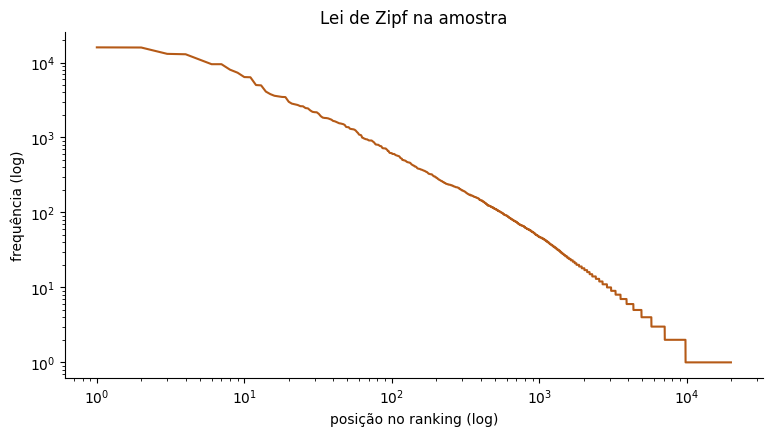

In [13]:
cont = collections.Counter(w for t in amostra["review_text"].str.lower() for w in re.findall(r"\w+", t))
freqs = np.array(sorted(cont.values(), reverse=True))
hapax = sum(1 for v in cont.values() if v == 1)
print(f"palavras distintas: {len(cont):,} | aparecem uma única vez: {hapax:,} ({hapax/len(cont):.0%})")
print("10 mais frequentes:", cont.most_common(10))
plt.loglog(np.arange(1, len(freqs) + 1), freqs, color="#B55A17")
plt.xlabel("posição no ranking (log)"); plt.ylabel("frequência (log)"); plt.title("Lei de Zipf na amostra")
plt.show()

## Bloco 2 · Contar palavras engana

### Problema
Quais palavras aparecem mais nas notas 1 e 5?

#### Entendendo o código

Comparar as palavras mais comuns nas notas 1 e 5, sem nenhum tratamento.

- `top_palavras(textos, k=10)` reúne o que já vimos: `re.findall` para separar palavras, `Counter` para contar e `most_common(k)` para pegar as `k` primeiras.
- `amostra.loc[amostra.overall_rating == 1, "review_text"]` seleciona as linhas com nota 1 **e** a coluna de texto, numa única operação: `.loc[linhas, colunas]`.
- `pd.DataFrame({"nota 1": [...], "nota 5": [...]})` monta uma tabela a partir de um dicionário: cada chave vira uma coluna.

In [14]:
def top_palavras(textos, k=10):
    return collections.Counter(w for t in textos for w in re.findall(r"\w+", t.lower())).most_common(k)

pd.DataFrame({
    "nota 1": [f"{w} ({n})" for w, n in top_palavras(amostra.loc[amostra.overall_rating == 1, "review_text"])],
    "nota 5": [f"{w} ({n})" for w, n in top_palavras(amostra.loc[amostra.overall_rating == 5, "review_text"])],
})

,nota 1,nota 5
0,o (5142),e (5312)
1,não (4720),de (4011)
2,e (4371),o (3978)
3,a (3754),a (3640)
4,de (3532),muito (3580)
5,que (3050),produto (3466)
6,produto (2916),do (2235)
7,com (2023),que (2233)
8,um (1359),é (2181)
9,é (1329),recomendo (1957)


As listas são quase iguais: a contagem bruta mostra a língua portuguesa, não o problema do cliente.

### Conceito: BoW e TF-IDF
- **Bag-of-Words:** cada documento vira um vetor de contagens, uma coluna por palavra do vocabulário.
- **TF-IDF:** pondera a contagem pela raridade no corpus.

$$\text{TF-IDF}(t,d) = \underbrace{\frac{\text{ocorrências de } t \text{ em } d}{\text{palavras em } d}}_{TF} \times \underbrace{\log_{10}\frac{N}{df(t)}}_{IDF}$$

### Solução: termos que distinguem as notas

#### Entendendo o código

TF-IDF na amostra pré-processada, e as palavras que distinguem cada nota.

- `min_df=5` ignora termos que aparecem em menos de 5 avaliações: erros de digitação e palavras raríssimas que só aumentariam a matriz.
- `ngram_range=(1, 2)` usa **n-gramas**: palavras isoladas (unigramas) e pares de palavras vizinhas (bigramas). Assim "não recomendo" vira uma coluna própria, diferente de "recomendo".
- `get_feature_names_out()` devolve o termo de cada coluna da matriz.
- `X.nnz` é o número de células diferentes de zero. **Densidade** = células preenchidas ÷ total de células. Por ser tão baixa, o scikit-learn guarda a matriz em formato **esparso**, que armazena só os valores diferentes de zero.
- Em `distintivos(nota)`: `X[alvo]` seleciona as linhas daquela nota, `X[~alvo]` as demais (`~` inverte a máscara), e `.mean(0)` calcula a média de cada coluna (eixo 0 = ao longo das linhas). A diferença entre as duas médias indica os termos típicos daquela nota.
- `np.asarray(...).ravel()` converte o resultado do formato esparso para um vetor NumPy comum.

**Observação:** o `TfidfVectorizer` não usa exatamente a fórmula da aula. Por padrão ele calcula o IDF com logaritmo natural e uma suavização, `ln((1 + N) / (1 + df)) + 1`, e depois normaliza cada linha para ter comprimento 1. A ideia é a mesma: termos frequentes no documento e raros no corpus pesam mais.

In [15]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(min_df=5, ngram_range=(1, 2))
X = tfidf.fit_transform(amostra["texto_limpo"])
vocab = np.array(tfidf.get_feature_names_out())
print("matriz:", X.shape, f"| densidade: {X.nnz / (X.shape[0] * X.shape[1]):.2%}")

def distintivos(nota, k=15):
    alvo = (amostra["overall_rating"] == nota).values
    dif = np.asarray(X[alvo].mean(0)).ravel() - np.asarray(X[~alvo].mean(0)).ravel()
    return list(vocab[np.argsort(-dif)[:k]])

pd.DataFrame({"nota 1": distintivos(1), "nota 5": distintivos(5)})

matriz: (20000, 9195) | densidade: 0.17%


,nota 1,nota 5
0,não,excelente
1,recebi,super
2,não recebi,recomendo
3,ainda,rápido
4,péssimo,antes
5,dia,qualidade
6,não recomendar,bom
7,nem,perfeito
8,avaliar,ótimo
9,comprei,recomendar


**Repare:** "entrega" aparece entre as palavras frequentes das duas notas. A mesma palavra serve a "entrega rápida" e a "entrega nunca chegou". Os bigramas (`ngram_range=(1, 2)`) ajudam, mas o limite da representação esparsa continua: ela não sabe que *entregue* e *chegou* falam da mesma coisa.

### Cálculo à mão (treino para a parte individual)

#### Entendendo o código

O TF-IDF calculado à mão, com a fórmula da aula, para uma avaliação.

- `df_termo` é a **frequência de documento** (*document frequency*): em quantas avaliações cada termo aparece. `set(t.split())` conta cada termo **uma vez por avaliação**, mesmo que ele se repita no texto.
- `.str.split().str.len().between(8, 15)` escolhe avaliações com 8 a 15 palavras, para a conta caber na tela.
- `palavras.count(termo)` conta quantas vezes o termo aparece no documento; dividido pelo total de palavras, dá o **TF**.
- `np.log10(N / df)` é o **IDF** da aula. Termos que aparecem em quase todos os documentos têm IDF perto de zero.
- `sort_values("TF-IDF", ascending=False)` ordena a tabela do maior peso para o menor.

Os valores não batem com a matriz `X` da célula anterior, por causa das diferenças do scikit-learn explicadas acima. A ordem relativa dos termos é parecida.

In [16]:
from collections import Counter
N = len(amostra)
df_termo = Counter(w for t in amostra["texto_limpo"] for w in set(t.split()))
doc = amostra.loc[(amostra["overall_rating"] == 1) & amostra["texto_limpo"].str.split().str.len().between(8, 15), "texto_limpo"].iloc[0]
palavras = doc.split()
print("documento:", doc, "\n")
linhas = []
for termo in sorted(set(palavras)):
    tf = palavras.count(termo) / len(palavras)
    idf = np.log10(N / df_termo[termo])
    linhas.append((termo, palavras.count(termo), df_termo[termo], round(tf, 3), round(idf, 3), round(tf * idf, 4)))
pd.DataFrame(linhas, columns=["termo", "vezes no doc", "df", "TF", "IDF", "TF-IDF"]).sort_values("TF-IDF", ascending=False)

documento: não indico compra relógio não vir cor descrição sem caixa vendedor não confiável 



,termo,vezes no doc,df,TF,IDF,TF-IDF
2,confiável,1,67,0.077,2.475,0.1904
7,relógio,1,114,0.077,2.244,0.1726
9,vendedor,1,193,0.077,2.015,0.1550
4,descrição,1,203,0.077,1.994,0.1533
0,caixa,1,220,0.077,1.959,0.1507
5,indico,1,292,0.077,1.836,0.1412
3,cor,1,321,0.077,1.795,0.1380
6,não,3,6552,0.231,0.485,0.1118
1,compra,1,1220,0.077,1.215,0.0934
8,sem,1,1238,0.077,1.208,0.0929


## Bloco 3 · Mesmo problema, palavras diferentes

### Problema
Duas reclamações reais da amostra:

#### Entendendo o código

Duas reclamações com o mesmo sentido e nenhuma palavra em comum.

- `TfidfVectorizer().fit(textos)` só aprende o vocabulário, sem guardar a matriz. Depois, `transform` converte as duas frases.
- `cosine_similarity(...)[0, 0]`: a função devolve uma matriz (aqui 1 × 1); `[0, 0]` pega o único valor.
- `la, lb = preprocessar([a, b])` usa **desempacotamento**: a função devolve uma lista com dois itens, e cada um vai para uma variável.
- `set(la.split()) & set(lb.split())` é a **interseção** de conjuntos: as palavras que as duas frases têm em comum.
- `... or "nenhuma"`: um conjunto vazio conta como falso em Python, então o `or` mostra o texto alternativo.

In [17]:
from sklearn.metrics.pairwise import cosine_similarity
a = "O pedido ainda não foi entregue.  Muito demorado. Estou no aguardo ainda."
b = "Continuo aguardando a justificativa para tanta demora de entrega."
tf_ab = TfidfVectorizer().fit(amostra["review_text"])
print("similaridade TF-IDF (texto bruto):", round(cosine_similarity(tf_ab.transform([a]), tf_ab.transform([b]))[0, 0], 2))
la, lb = preprocessar([a, b])
print("lematizadas:", la, "|", lb)
print("similaridade TF-IDF (lematizado):", round(cosine_similarity(tfidf.transform([la]), tfidf.transform([lb]))[0, 0], 2))
print("palavras em comum depois de lematizar:", set(la.split()) & set(lb.split()) or "nenhuma")

similaridade TF-IDF (texto bruto): 0.0
lematizadas: pedido ainda não entregar demorado aguardo ainda | continuar aguardar justificativa tanto demor entrega
similaridade TF-IDF (lematizado): 0.0
palavras em comum depois de lematizar: nenhuma


### Conceito: embeddings
Um modelo de embeddings transforma cada texto num **vetor denso** (aqui, 384 números) treinado para que textos com significado parecido fiquem próximos. A proximidade é medida pelo **cosseno** entre os vetores.

Usamos o modelo multilíngue `paraphrase-multilingual-MiniLM-L12-v2`, pequeno o suficiente para rodar em CPU.

#### Entendendo o código

**Embeddings** com um modelo pré-treinado.

- `SentenceTransformer("sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2")` baixa o modelo do repositório Hugging Face na primeira execução (algumas centenas de MB) e o carrega. É uma rede neural treinada para que **frases com o mesmo sentido** fiquem com vetores próximos, inclusive em português.
- `modelo.encode([a, b], normalize_embeddings=True)` devolve um vetor de **384 números** para cada frase. Com `normalize_embeddings=True`, cada vetor tem comprimento 1.
- `ea @ eb` é o **produto escalar** (o operador `@` multiplica vetores e matrizes). Para vetores de comprimento 1, o produto escalar **é** o cosseno, sem conta extra.

In [18]:
from sentence_transformers import SentenceTransformer
modelo = SentenceTransformer("sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2")
ea, eb = modelo.encode([a, b], normalize_embeddings=True)
print("similaridade de cosseno com embeddings:", round(float(ea @ eb), 2))

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

... (4 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

similaridade de cosseno com embeddings: 0.76


Agora a amostra inteira. Em CPU leva alguns minutos; com GPU no Colab (Ambiente de execução → Alterar tipo → T4), segundos.

#### Entendendo o código

Embeddings da amostra inteira.

- `batch_size=128` processa 128 textos por vez: lotes maiores aproveitam melhor a GPU.
- `show_progress_bar=True` mostra uma barra de progresso.
- `E.shape` deve ser `(20000, 384)`: uma linha por avaliação, 384 colunas. Ao contrário do TF-IDF, é uma matriz **densa**: quase nenhum valor é zero.

Dica: guarde o resultado para não recalcular nas próximas aulas, com `np.save("embeddings.npy", E)` (de preferência no Google Drive) e, depois, `E = np.load("embeddings.npy")`.

In [19]:
%%time
E = modelo.encode(amostra["review_text"].tolist(), batch_size=128, normalize_embeddings=True, show_progress_bar=True)
E.shape

Batches:   0%|          | 0/157 [00:00<?, ?it/s]

CPU times: user 17min 1s, sys: 1min 8s, total: 18min 9s
Wall time: 18min 48s


(20000, 384)

### Solução: busca semântica

#### Entendendo o código

Uma função de **busca** que compara os dois métodos lado a lado.

- A consulta passa pelo **mesmo** tratamento dos documentos: `preprocessar` e `tfidf.transform` no TF-IDF, `modelo.encode` nos embeddings. Consulta e documentos precisam estar na mesma representação; caso contrário, a comparação não faz sentido.
- `E @ q_e.T` multiplica a matriz de embeddings (20.000 × 384) pela consulta transposta (384 × 1) e devolve os 20 mil scores de uma vez. `.T` é a **transposição** (troca linhas por colunas).
- `for nome, sc in [("TF-IDF", ...), ("embeddings", ...)]` percorre uma lista de pares, desempacotando cada par em duas variáveis.
- `float(sc[i])` converte o número do formato NumPy para um número Python comum antes de arredondar.

In [20]:
def buscar(consulta, k=5):
    q_t = tfidf.transform(preprocessar([consulta]))
    q_e = modelo.encode([consulta], normalize_embeddings=True)
    res = []
    for nome, sc in [("TF-IDF", cosine_similarity(q_t, X).ravel()), ("embeddings", (E @ q_e.T).ravel())]:
        for i in np.argsort(-sc)[:k]:
            res.append({"método": nome, "score": round(float(sc[i]), 2), "nota": amostra.overall_rating[i], "texto": amostra.review_text[i][:120]})
    return pd.DataFrame(res)

buscar("o produto não chegou")

,método,score,nota,texto
0,TF-IDF,0.78,1,"ATÉ AGORA, NÃO CHEGOU.NÃO CHEGOU.NÃO CHEGOU. NÃO CHEGOU.NÃO CHEGOU.NÃO CHEGOU."
1,TF-IDF,0.74,1,O PRODUTO AINDA NÃO CHEGOU!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
2,TF-IDF,0.62,1,"Esse produto eu pedi cancelamento, ainda não chegou para mim... não tem como recomendar se não chegou."
3,TF-IDF,0.61,1,Estou desesperado esperado E O PRODUTO NAO CHEGOU]
4,TF-IDF,0.60,1,"não chegou como vou avaliar, isto é se chegar não chegou o produto deve ter sido extraviado"
5,embeddings,0.83,1,Até o momento o produto não foi entregue. Aguardando a um mês
6,embeddings,0.81,1,Não comprem. O produto não funciona. Produto de pèssima qualidade
7,embeddings,0.80,1,Venho informar que o respectivo produto não foi entregue.
8,embeddings,0.79,1,o produto não chegou até hoje. GOSTARIA DE SABER ONDE ESTA?
9,embeddings,0.79,4,Infelizmente não recebi o produto. Fornecedor não tinha como entregar


#### Entendendo o código

A mesma função `buscar`, com outra consulta. Compare as duas listas: onde cada método acerta e onde erra?

In [21]:
buscar("chegou quebrado")

,método,score,nota,texto
0,TF-IDF,0.77,1,"embalou meu tripe muito mal, e ele chegou quebrado"
1,TF-IDF,0.61,1,Chegou quebrado e até o momento não trocaram o produto
2,TF-IDF,0.53,1,"Demorou muito pra chegar ,e quando chegou , produto quebrado em vários lugares"
3,TF-IDF,0.52,1,AS XICARAS SAO FRAGEIS CHEGARAM QUEBRADAS PEÇO DEVOLUÇAO DA QUANTIA PAGA COMO FAÇO PARA DEVOLVER..............
4,TF-IDF,0.49,1,"O produto chegou quebrado e estou esperando uma resposta há quase um mês, que foi quando postei o produto para a avaliaç"
5,embeddings,0.70,1,Cabo veio quebradoooooooooooooooooooooooooooooooooooooooooooooooo
6,embeddings,0.70,1,"embalou meu tripe muito mal, e ele chegou quebrado"
7,embeddings,0.67,3,Mto bom produto. Porém o meu jarro veio arranhado.
8,embeddings,0.66,1,ruimruimruimruimruim ruimruimruimruimruim ruim ruim ruim
9,embeddings,0.65,1,Veio com defeito e o acabamento da peça deixou muito a desejar


**Leitura crítica:** os embeddings encontram sinônimos ("não foi entregue", "não recebi"), mas também erram, trazendo às vezes uma reclamação de outro tipo. E textos em CAIXA ALTA tendem a ficar próximos entre si, qualquer que seja o assunto: a normalização importa também para embeddings.

### O mapa do espaço
Projetamos 5 mil vetores em 2D com UMAP. Cada ponto é uma avaliação; a cor é a nota.

#### Entendendo o código

Um mapa 2D das avaliações com **UMAP**, uma técnica de **redução de dimensionalidade**: projeta os 384 números de cada avaliação em 2, tentando manter perto o que estava perto.

- `np.random.RandomState(0).choice(len(amostra), 5000, replace=False)` sorteia 5 mil posições sem repetição, com semente fixa. Usamos só 5 mil para o gráfico ficar legível e rápido.
- `E[idx]` seleciona as linhas da matriz cujas posições estão em `idx`.
- Parâmetros do `umap.UMAP`:
  - `n_neighbors=30`: quantos vizinhos cada ponto considera. Valores menores realçam a estrutura local; maiores, a global.
  - `min_dist=0.1`: o quanto os pontos podem ficar juntos no mapa.
  - `metric="cosine"`: a mesma medida usada na busca.
- `plt.scatter(x, y, s=4, c=cores, alpha=0.7)` desenha os pontos: `s` é o tamanho, `c` a cor de cada ponto e `alpha` a transparência.

**Cuidado ao interpretar:** distâncias no mapa 2D são aproximadas. Dois pontos vizinhos de verdade podem aparecer afastados.

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


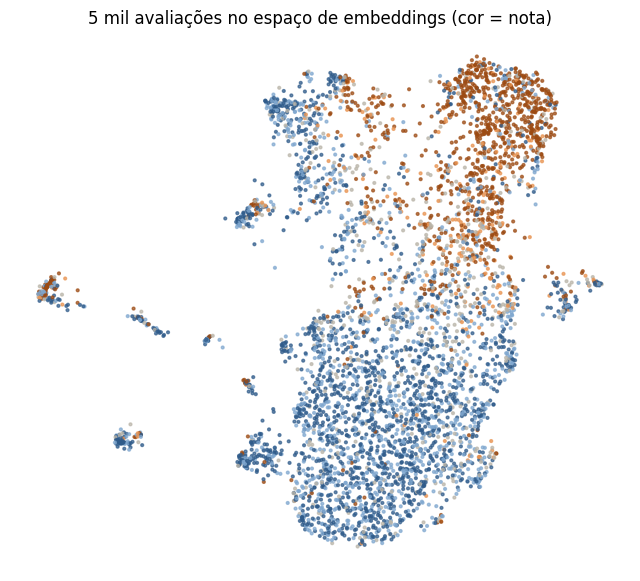

In [22]:
import umap
idx = np.random.RandomState(0).choice(len(amostra), 5000, replace=False)
coords = umap.UMAP(n_neighbors=30, min_dist=0.1, metric="cosine", random_state=42).fit_transform(E[idx])
cores = {1: "#9C4A12", 2: "#E8924F", 3: "#B9B4A8", 4: "#7FA7CF", 5: "#2F5B8A"}
plt.figure(figsize=(8, 7))
plt.scatter(coords[:, 0], coords[:, 1], s=4, c=[cores[n] for n in amostra.overall_rating.values[idx]], alpha=0.7)
plt.title("5 mil avaliações no espaço de embeddings (cor = nota)"); plt.axis("off"); plt.show()

### Outras medidas de similaridade
O cosseno serve para vetores densos. Para outros problemas, outras medidas:
- **Jaccard:** sobreposição de conjuntos de palavras. Boa para achar textos quase duplicados.
- **Levenshtein:** número de edições entre duas strings. Boa para erros de digitação e nomes de produtos.

#### Entendendo o código

Duas medidas de similaridade para outros problemas.

- **Jaccard** = palavras em comum ÷ palavras no total, ou seja, `len(A & B) / len(A | B)` com conjuntos. Ignora a ordem e a frequência: serve para achar textos quase duplicados.
- **Levenshtein** é o número mínimo de edições (inserir, apagar ou trocar um caractere) para transformar uma string na outra. Serve para erros de digitação e nomes de produtos.
- A função `levenshtein` usa **programação dinâmica**: monta, linha a linha, uma tabela com as distâncias entre todos os começos das duas palavras. `ant` guarda a linha anterior e `atual` a linha em construção.
- Em cada posição, `min(apagar + 1, inserir + 1, trocar + (cs != ct))`. `(cs != ct)` vale 1 se os caracteres são diferentes e 0 se são iguais, porque Python trata `True` como 1.
- `enumerate(s, 1)` percorre a string devolvendo também a posição, começando em 1.

Em projetos reais, use bibliotecas otimizadas, como `rapidfuzz`.

In [23]:
def jaccard(x, y):
    A, B = set(x.lower().split()), set(y.lower().split())
    return len(A & B) / len(A | B)

def levenshtein(s, t):
    ant = list(range(len(t) + 1))
    for i, cs in enumerate(s, 1):
        atual = [i]
        for j, ct in enumerate(t, 1):
            atual.append(min(ant[j] + 1, atual[j - 1] + 1, ant[j - 1] + (cs != ct)))
        ant = atual
    return ant[-1]

print("Jaccard:", round(jaccard("produto chegou no prazo recomendo", "chegou no prazo recomendo o produto"), 2))
print("Levenshtein smartfone x smartphone:", levenshtein("smartfone", "smartphone"))

Jaccard: 0.83
Levenshtein smartfone x smartphone: 2


---
# Etapa 1 do projeto · entrega até 23/11, 23h59

A partir daqui, o notebook é de vocês. As células abaixo seguem os **7 itens do checklist** apresentado no laboratório, na mesma ordem e com a mesma numeração.

**Como entregar**
1. Salvem uma cópia deste notebook no repositório do grupo (*Arquivo › Salvar uma cópia no GitHub*).
2. Preencham cada item: as células de código têm comentários com o que fazer; as células **Resposta do grupo** são para o texto.
3. Rodem o notebook inteiro antes de entregar, para que as saídas fiquem salvas.
4. Entreguem o link do repositório, com um README curto (integrantes e onde usaram IA, se usaram).

| # | Item | Critério de aceite |
|---|---|---|
| 1 | Amostra | Amostra própria (outra semente e outro tamanho), justificada em um parágrafo |
| 2 | Exploração | Notas, comprimento, vazios e duplicados, com gráficos |
| 3 | Catálogo de sujeira | 30 avaliações lidas e a tabela preenchida |
| 4 | Pipeline | Cada decisão justificada e um exemplo do que a limpeza apagaria |
| 5 | Representações | TF-IDF e embeddings da amostra, com a densidade da matriz |
| 6 | Busca | Três consultas do grupo, top 5 dos dois métodos e análise |
| 7 | Individual | TF-IDF à mão de três termos e uma decisão explicada |

Itens 1 a 6: grupo (10 pontos). Item 7: individual (5 pontos).

## Item 1 · Amostra

**O que fazer:** criar a amostra **do grupo**, que será usada no projeto inteiro.

**Obrigatório:** a amostra não pode ser a da aula.
- **Semente:** escolham uma diferente de 42 e guardem na variável `SEMENTE`. Usem a mesma em todo o notebook.
- **Tamanho:** diferente de 20 mil. Entre 5 mil e 30 mil costuma rodar bem no Colab.
- **Critério:** livre, desde que justificado. Pode ser aleatória, estratificada por nota (mesma quantidade de cada nota) ou por categoria de produto.

Todos os itens seguintes (2 a 7) usam esta amostra: a variável `amostra` é substituída aqui.

**Critério de aceite:** amostra própria (outra semente e outro tamanho), justificada em um parágrafo.

In [32]:
# Item 1 · Amostra do grupo (obrigatório: semente diferente de 42 e tamanho diferente de 20 mil)
# 1) Definam a semente do grupo:
SEMENTE = 84

#
# 2) Criem a amostra (escolham UM critério). Exemplos:
amostra = df.sample(40000, random_state=SEMENTE).reset_index(drop=True)                                      # aleatória
amostra["n_palavras"] = amostra["review_text"].str.split().str.len()
#
# 3) Conferência (descomentem e rodem):
assert SEMENTE != 82 and len(amostra) != 20_000, "A amostra precisa ser diferente da usada em aula"
print(amostra.shape); amostra["overall_rating"].value_counts().sort_index()

(40000, 15)


,count
overall_rating,
1,7822
2,2485
3,4980
4,10121
5,14592


**Resposta do grupo (Item 1):** qual a semente, o tamanho e o critério? Por que essa escolha atende ao problema (por exemplo, equilíbrio entre notas, tempo de execução no Colab, foco em reclamações)?

**Semente**: 84 <br>
**tamanho**: 40.000<br>
**Critério**: Aleatória<br><br>
_Dobramos a amostra para aumentar a janela de contexto_.

## Item 2 · Exploração

**O que fazer:** descrever a amostra com números e gráficos.

- Distribuição das notas e da recomendação (`recommend_to_a_friend`).
- Comprimento dos textos (em palavras).
- Quantos textos vazios e duplicados existiam no dataset original.
- A seção 1 já tem parte disso: podem reaproveitar o código, mas comentem o que observam.

**Critério de aceite:** notas, comprimento, vazios e duplicados, com gráficos.

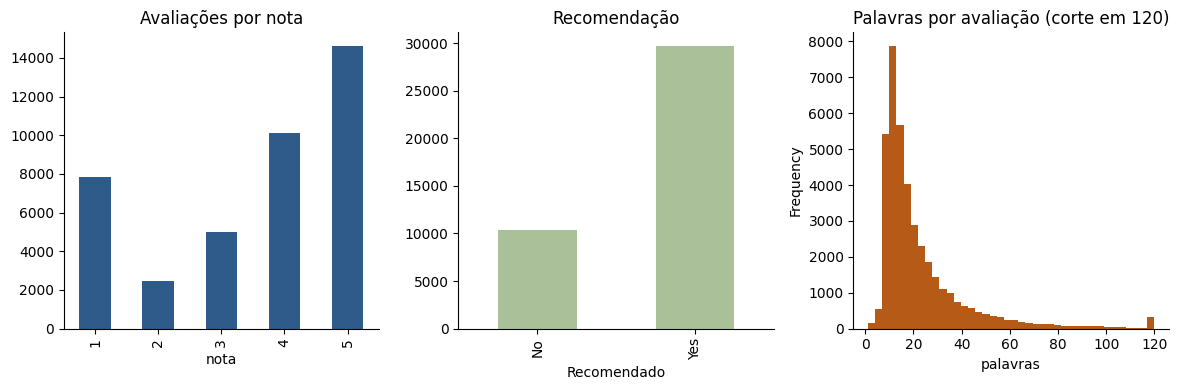

Qtd vazios: 3275
Qtd duplicados: 5649


In [33]:
fig, ax = plt.subplots(1, 3, figsize=(12, 4))

# Avaliação por nota
amostra["overall_rating"].value_counts().sort_index().plot.bar(ax=ax[0], color="#2F5B8A")
ax[0].set_title("Avaliações por nota"); ax[0].set_xlabel("nota")

# Recomendação
amostra["recommend_to_a_friend"].value_counts().sort_index().plot.bar(ax=ax[1], color="#aac099")
ax[1].set_title("Recomendação"); ax[1].set_xlabel("Recomendado")

# Palavaras por avaliação
amostra["n_palavras"].clip(upper=120).plot.hist(bins=40, ax=ax[2], color="#B55A17")
ax[2].set_title("Palavras por avaliação (corte em 120)"); ax[2].set_xlabel("palavras")

# Exibir gráfico
plt.tight_layout(); plt.show()
amostra["n_palavras"].describe()

# Contagem dos vazios
df_limpo = df_full[df_full["review_text"].notna() & (df_full["review_text"].str.strip() != "")]
print("Qtd vazios:", len(df_full) - len(df_limpo))

# Contagem dos duplicados
df_limpo = df_limpo.drop_duplicates(subset="review_text")
print("Qtd duplicados:", len(df_full) - len(df_limpo))

**Resposta do grupo (Item 2):** o que os números mostram? As notas estão equilibradas? As avaliações são curtas ou longas? Isso muda alguma decisão daqui para a frente?

_A partir de uma nova amostra, a avaliação positiva obteve um incremento significativa. Portanto as notas ficaram desequilibradas.<br>As avaliações são **curtas**, contendo a maioria 15 palavras por avaliação.<br>Ainda não sei_<br><br>
***Contagem***<br>
Qtd vazios: **3275**<br>
Qtd duplicados: **5649**

## Item 3 · Catálogo de sujeira

**O que fazer:** ler 30 avaliações e registrar os problemas encontrados.

1. Sorteiem 30 avaliações da amostra do grupo, com a `SEMENTE` do Item 1.
2. Leiam todas, com atenção.
3. Para cada tipo de problema, registrem: o problema, um exemplo real, em quantas das 30 ele aparece e a **decisão** do grupo.

O que procurar: abreviações, caixa alta, pontuação repetida, letras esticadas, erros de digitação, emojis, números e preços, e **dados pessoais** (nomes, telefones, e-mails).

**Critério de aceite:** 30 avaliações lidas e a tabela preenchida. A coluna **decisão** é a que mais vale: ela precisa dizer o que se ganha e o que se perde, não apenas "remover".

In [34]:
# Item 3 · Catálogo de sujeira
# 1) Sorteiem e imprimam as 30 avaliações (troquem a semente):
SEMENTE = 84
lidas = amostra.sample(30, random_state=SEMENTE)
for r in lidas.itertuples():
  if( r.overall_rating <= 2):
    print(f"{r.overall_rating}★ | {r.review_text}")

sinais = {
    "CAIXA ALTA": amostra["review_text"].str.isupper(),
    "pontuação repetida (!!!, ???)": amostra["review_text"].str.contains(r"[!?]{3,}"),
    "abreviações (vc, q,d, pq, tb, msm)": amostra["review_text"].str.contains(r"\b(?:vc|q|d|pq|tb|td|msm)\b", case=False),
    "letras esticadas (ruimmmm)": amostra["review_text"].str.contains(r"([a-z])\1{3,}", case=False),
    "URL": amostra["review_text"].str.contains(r"https?://|www\.", case=False),
    "palavra 'não'": amostra[ "review_text"].str.contains(r"\b(não|nao|naum)\b",case=False),
    "e-mails": amostra["review_text"].str.contains(r"\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Z|a-z]{2,}\b", case=False),
    "telefone": amostra["review_text"].str.contains(r"\b(?:\(\d{2}\)\s?)?\d{4,5}\s?-?\s?\d{4}\b", case=False),
}
pd.Series({k: int(v.sum()) for k, v in sinais.items()}, name="avaliações").to_frame()


# 2) Preencham o catálogo. A primeira linha é um exemplo; acrescentem uma linha por problema encontrado:
catalogo = pd.DataFrame([
    {"problema": "negação sem acento",
     "exemplo real": "nao teria feito a segunda compra",
     "quantas em 30": 1,
     "decisão": "unificar 'nao' em 'não' e preservar a negação"},

    {"problema": "falta de acentuação",
     "exemplo real": "otimo para navegar",
     "quantas em 30": 6,
     "decisão": "padronizar a acentuação quando possível"},

    {"problema": "erros de digitação",
     "exemplo real": "supet indico",
     "quantas em 30": 3,
     "decisão": "corrigir erros evidentes sem alterar o sentido"},

    {"problema": "espaços duplicados",
     "exemplo real": "A bateria não dura  nada",
     "quantas em 30": 8,
     "decisão": "substituir espaços repetidos por um único espaço"},

    {"problema": "pontuação repetida",
     "exemplo real": "Tamanho, qualidade e design ....",
     "quantas em 30": 4,
     "decisão": "remover repetições desnecessárias de pontuação"},

    {"problema": "palavras grudadas",
     "exemplo real": "aentrega",
     "quantas em 30": 3,
     "decisão": "separar palavras quando for possível identificar"},

    {"problema": "letras repetidas sem sentido",
     "exemplo real": "bbbbbbbbbbbbbbbbb",
     "quantas em 30": 1,
     "decisão": "remover sequências sem significado"},

    {"problema": "nota contraditória com o texto",
     "exemplo real": "5 estrelas: Super arrependido",
     "quantas em 30": 1,
     "decisão": "manter o texto e a nota para identificar divergências"}
])
catalogo

1★ | Até hoje a americana.com não prontificou em solucionar o problema , é negligente mesmo após das reclamações feitas pelo meio eletrônico.
1★ | Na foto aparece com caixa e veio sem a caixa, sem manual, só num papelão.
1★ | Chegou hoje peças batidas ,danificadas aguardando para ver se vão trocar .. Aí volto a dar minha opinião!  Site móveis web
2★ | Não gostei do vidro do relógio e arredondado e tem grau


/tmp/ipykernel_423/4055003179.py:13: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "letras esticadas (ruimmmm)": amostra["review_text"].str.contains(r"([a-z])\1{3,}", case=False),
/tmp/ipykernel_423/4055003179.py:15: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  "palavra 'não'": amostra[ "review_text"].str.contains(r"\b(não|nao|naum)\b",case=False),


,problema,exemplo real,quantas em 30,decisão
0,negação sem acento,nao teria feito a segunda compra,1,unificar 'nao' em 'não' e preservar a negação
1,falta de acentuação,otimo para navegar,6,padronizar a acentuação quando possível
2,erros de digitação,supet indico,3,corrigir erros evidentes sem alterar o sentido
3,espaços duplicados,A bateria não dura nada,8,substituir espaços repetidos por um único espaço
4,pontuação repetida,"Tamanho, qualidade e design ....",4,remover repetições desnecessárias de pontuação
5,palavras grudadas,aentrega,3,separar palavras quando for possível identificar
6,letras repetidas sem sentido,bbbbbbbbbbbbbbbbb,1,remover sequências sem significado
7,nota contraditória com o texto,5 estrelas: Super arrependido,1,manter o texto e a nota para identificar divergências


**Resposta do grupo (Item 3):** qual problema foi o mais frequente? Algum surpreendeu? Encontraram dados pessoais?

_O problema mais frequente foi a **espaços duplicados**_.<br>A maior supresa é a distorção do sentido da frase ou remover o a palavra **não** da frase. <br>Não foram encontrados falta de pontuação.

## Item 4 · Pipeline

**O que fazer:** adaptar o pré-processamento ao que o catálogo mostrou.

- Copiem para a célula abaixo a função `normalizar` e o conjunto `STOP` (Bloco 1) e alterem o que for preciso. Cada alteração deve vir de uma linha do catálogo.
- Reapliquem o pipeline à amostra e meçam o vocabulário antes e depois.
- Mostrem **um exemplo de algo que a limpeza apaga e não deveria apagar** (uma avaliação antes e depois, com o que se perdeu).

**Critério de aceite:** cada decisão justificada e um exemplo do que a limpeza apagaria.

In [35]:
# Item 4 · Pipeline
# 1) Redefinam normalizar() e STOP com as decisões do grupo (copiem do Bloco 1 e alterem).
#    A função preprocessar() do Bloco 1 usa as versões novas automaticamente.
import unicodedata

STOP = (stop_nltk | {"produto", "americanas"}) - {"não", "nao", "nem", "sem", "mas"}

def normalizar(texto):
    t = texto.lower()
    t = re.sub(r"https?://\S+|www\.\S+", " ", t)      # URLs
    t = re.sub(r"([a-zà-ú])\1{2,}", r"\1", t)          # ruimmmm -> ruim
    t = re.sub(r"\bnao\b", "não", t)                   # unifica a negação
    t = re.sub(r"\b(vc)\b", "você", t)
    t = re.sub(r"\b(q)\b", "que", t)
    t = re.sub(r"\b(pq)\b", "porque", t)

    t = re.sub(r"\s+", " ", t)
    t = re.sub(r"\bsupet\b", "super", t)
    t = re.sub(r"\bta\b", "está", t)

    return t

def preprocessar(textos, lematizar=True):
    saida = []
    for doc in nlp.pipe((normalizar(t) for t in textos), batch_size=500):
        toks = []
        for tok in doc:
            if tok.is_alpha:
                # o spaCy expande contrações ("dos" -> "de o"): separamos as partes
                toks.extend((tok.lemma_ if lematizar else tok.text).split())
        saida.append(" ".join(w for w in toks if w not in STOP))
    return saida

# 2) Reapliquem à amostra:
amostra["texto_limpo"] = preprocessar(amostra["review_text"].tolist())

# 3) Tamanho do vocabulário antes e depois (função tamanho_vocab do Bloco 1).
def tamanho_vocab(textos):
    return len({w for t in textos for w in t.split()})

amostra[["review_text", "texto_limpo"]].head(5)

print("Antes:", tamanho_vocab(amostra["review_text"]))
print("Depois:", tamanho_vocab(amostra["texto_limpo"]))

# 4) Exemplo do que a limpeza apaga e não deveria: escolham uma avaliação e mostrem as duas versões:
etapas = {
    "bruto (split)": amostra["review_text"].tolist(),
    "minúsculas": amostra["review_text"].str.lower().tolist(),
    "normalizado": [normalizar(t) for t in amostra["review_text"]],
    "pipeline completo": amostra["texto_limpo"].tolist(),
}
pd.Series({k: tamanho_vocab(v) for k, v in etapas.items()}, name="palavras distintas").to_frame()

i = amostra[amostra["review_text"].str.contains("30 dias", na=False)].index[0]
print("ORIGINAL:", amostra.review_text[i]); print("LIMPO   :", amostra.texto_limpo[i])

Antes: 66692
Depois: 20294
ORIGINAL: Estou a 30 dias sem receber o produto e a Americanas.com NÃO se pronuncia sobre o motivo do atraso, lamentável.
LIMPO   : dia sem receber não pronunciar sobre motivo atraso lamentável


**Resposta do grupo (Item 4):** liste cada decisão do pipeline com a justificativa (o que ganha, o que perde). Depois, explique o exemplo: o que a limpeza apagou e por que isso importava?

|Decisão|Justificativa|
|-------|-------------|
|Converter textos para minúsculas|Padroniza as palavras e reduz o vocabulário, mas perde a diferenciação por maiúsculas.|
|Remover stopwords|Elimina palavras pouco informativas e reduz o ruído, mas pode retirar parte do contexto.|
|Preservar "não", "nem", "sem" e "mas"|Mantém informações importantes para o sentido da avaliação, embora preserve palavras frequentes.|
|Remover URLs|Elimina informações que geralmente não contribuem para a análise, mas pode apagar referências úteis.|
|Reduzir letras repetidas|Corrige exageros na escrita, mas pode perder a intensidade de algumas expressões.|
|Padronizar "nao" para "não"|Unifica diferentes formas da mesma palavra, sem perda relevante de significado.|
|Corrigir abreviações como "vc", "q" e "pq"|Facilita a interpretação dos textos, mas algumas abreviações podem ter significados diferentes dependendo do contexto.|
|Remover espaços duplicados|Padroniza a escrita e facilita o processamento, sem perda relevante de informação.|
|Corrigir "supet" para "super" e "ta" para "está"|Corrige erros e expressões informais, mas pode alterar termos em outros contextos.|
|Aplicar lematização|Agrupa diferentes formas de uma palavra, reduzindo o vocabulário, mas perde informações sobre flexões verbais.|
|Remover números e pontuação|Simplifica os textos, mas pode eliminar informações importantes, como prazos e valores.|

_Um dos registros analisados aponta uma espera de quase 30 dias. Durante o pré-processamento, o valor de '30' acaba eliminado pela filtragem de tokens  alfabéticos. Eliminar esse dado compromete a análise, visto que a duração da espera contextualiza a severidade do problema._

## Item 5 · Representações

**O que fazer:** representar a amostra (já com o pipeline do grupo) de duas formas.

- **TF-IDF** sobre `texto_limpo`, com os parâmetros que o grupo escolher (`min_df`, `ngram_range`).
- **Embeddings** sobre o texto original (`review_text`), com o modelo do Bloco 3.
- Reportem o formato das duas matrizes e a **densidade** da matriz TF-IDF.
- Salvem os embeddings (`np.save`), de preferência no Google Drive: eles voltam na Etapa 2.

**Critério de aceite:** TF-IDF e embeddings da amostra, com a densidade da matriz.

In [36]:
# Item 5 · Representações
# 1) TF-IDF (Bloco 2):
tfidf = TfidfVectorizer(min_df=3, ngram_range=(1, 2))
X = tfidf.fit_transform(amostra["texto_limpo"])
print("TF-IDF:", X.shape, f"| densidade: {X.nnz / (X.shape[0] * X.shape[1]):.2%}")
#
# 2) Embeddings (Bloco 3). Com GPU, poucos segundos:
E = modelo.encode(amostra["review_text"].tolist(), batch_size=128, normalize_embeddings=True, show_progress_bar=True)
print("embeddings:", E.shape)
#
# 3) Salvar para a Etapa 2:
np.save("embeddings.npy", E)

TF-IDF: (40000, 31993) | densidade: 0.06%


Batches:   0%|          | 0/313 [00:00<?, ?it/s]

embeddings: (40000, 384)


**Resposta do grupo (Item 5):** quais parâmetros usaram no TF-IDF e por quê? Comparem as duas representações: tamanho, densidade e o que cada uma consegue ou não capturar.

_Escrevam aqui._

## Item 6 · Busca

**O que fazer:** comparar TF-IDF e embeddings em três consultas escolhidas pelo grupo.

- Sugestão: uma consulta sobre **entrega**, uma sobre **defeito** e uma sobre **atendimento**.
- Usem a função `buscar()` do Bloco 3: ela mostra os 5 primeiros resultados de cada método lado a lado.
- **Leiam** os resultados: score alto não significa acerto.

**Critério de aceite:** três consultas do grupo, top 5 dos dois métodos e análise.

In [37]:
# Item 6 · Busca
# Troquem pelas consultas do grupo. display() mostra cada tabela dentro do laço.
for consulta in ["entrega atrasada", "produto com defeito", "atendimento ruim"]:
  display(buscar(consulta))

,método,score,nota,texto
0,TF-IDF,1.00,1,Entrega ATRASADA!!!!!!!!#!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
1,TF-IDF,0.63,3,"O produto é bom, porém foi entregue atrasado, após o natal."
2,TF-IDF,0.52,1,Não recebi o produto entrega atrasada prometeram entregar dia 16 e até agora nada
3,TF-IDF,0.47,1,"Quase 30 dias para entregar e atrasam o prazo, não recomendo, se for na aliexpress de Navio chega mais rápido."
4,TF-IDF,0.39,1,Não posso avaliar um produto que não foi entregue. Atrasaram a entrega e nunca me deram uma satisfação. Estou aguardando
5,embeddings,0.76,4,"Produto ótimo. Mas, a demora na entrega é muito ruim!"
6,embeddings,0.72,1,Péssimo atendimento .. demora na entrega .. não recomendo
7,embeddings,0.72,4,"Produto muito bom. Só a entrega que atrasou muito, mas culpa do Correio."
8,embeddings,0.72,1,Não recebi a encomenda Ainda ! Ja passou o prazo de entrega! Aguardo retorno!
9,embeddings,0.72,5,"Produto igual o descrito, teve atraso na entrega mais o atraso ocorreu por conta dos correios."


,método,score,nota,texto
0,TF-IDF,0.58,1,O produto veio com defeito Fgyujhfdjkmbcxbkjgxvfgiudcbnvxcvg bhfdddfcgn nnhffff bbgggggt bhfdssdf hgsdhjhvvh jgccxfghk n
1,TF-IDF,0.58,1,Produto veio com defeito.
2,TF-IDF,0.46,1,"veeio com defeito veio com defeito, veio com defeito , ta bom ou ainda ta curto ]"
3,TF-IDF,0.43,1,"Produto está com defeito, encaminharei para a garantia!"
4,TF-IDF,0.38,1,Muito frágil.Não recomendo. Produto já veio com defeito.
5,embeddings,0.80,1,O produto chegou com defeito e peças soltas. Não recomendo
6,embeddings,0.80,1,Produto veio com defeito.
7,embeddings,0.79,1,produto veio com defeito não funcionava foi necessária sua devolução
8,embeddings,0.78,2,O produto já veio com defeito ! To tentando a troca com a lojas
9,embeddings,0.77,1,Produto com defeito e reclamaçåo sem retorno do vendedor


,método,score,nota,texto
0,TF-IDF,0.92,1,Atendimento tuim Atendimento ruim Atendimento ruim
1,TF-IDF,0.42,1,ruim reuimruim ruim ruim ruim ruim bbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbbb bbbbbbbbbbb
2,TF-IDF,0.31,1,netbook muito ruim pequeno programação ruim windo 10 muito ruim.
3,TF-IDF,0.30,3,"O produto deve ser bom, mas a entrega... PÉSSIMA! Já alteraram o prazo de entrega, já está em atraso.. E não consigo ate"
4,TF-IDF,0.29,1,"O produto é horrível, simplesmente um lixo! Com menos de um mês de uso a bateria viciou, agora minimamente para ligar te"
5,embeddings,0.92,1,Atendimento tuim Atendimento ruim Atendimento ruim
6,embeddings,0.74,1,Produto não chega não recomendo péssimo atendimento
7,embeddings,0.71,1,Péssimo serviço de entrega. Péssimo serviço de entrega. Péssimo serviço de entrega...
8,embeddings,0.68,1,Péssima para fechar o sinto ...a regulagem pior ainda
9,embeddings,0.66,1,Pessimo. O atendimento da empresa na devolução eh pior ainda


**Resposta do grupo (Item 6):** para cada consulta, quantos dos 5 resultados de cada método são realmente relevantes? Onde cada método acertou e onde errou? Mostrem exemplos. Qual método o grupo usaria no projeto, e por quê?

| Consulta | Relevantes TF-IDF (de 5) | Relevantes embeddings (de 5) |
|---|---|---|
|  Entrega atrasada|  5| 5 |
|  Produto com defeito| 5 | 5 |
|  Atendimento ruim| 1 | 3 |

_**Análise**: Os dois métodos tiveram bons resultados nas consultas sobre entrega e defeito. Na busca por atendimento ruim, o TF-IDF trouxe avaliações sobre produtos ruins, sem relação com atendimento. Os embeddings também apresentaram resultados incorretos, mas encontraram mais avaliações relacionadas ao tema._

_**Escolha do grupo**: Utilizaríamos os embeddings, pois conseguiram encontrar mais resultados relevantes, mesmo quando as avaliações usavam palavras diferentes das pesquisadas._

## Item 7 · Individual (5 pontos)

Cada integrante faz a sua parte na subseção com o seu nome. Grupos menores apagam as subseções que sobrarem.

**A · TF-IDF à mão:** escolham uma avaliação **já pré-processada** (diferente da usada em aula) e três termos dela. Para cada termo, mostrem a conta, não só o resultado:

- TF = vezes no documento ÷ palavras no documento
- IDF = log10(N ÷ df), com N = tamanho da amostra e o **df real** da amostra (dicionário `df_termo`, do Bloco 2)
- TF-IDF = TF × IDF

**B · Uma decisão explicada:** um parágrafo sobre uma decisão de pré-processamento do grupo: o que ela ganha, o que ela perde e por que vale a pena no nosso problema.

**Critério de aceite:** TF-IDF à mão de três termos e uma decisão explicada.

In [43]:
# Item 7 · Apoio para a parte A: o código só busca os dados; a conta vai no texto da sua subseção.
# Recalculem df_termo se o grupo mudou o pipeline no Item 4:

df_termo = Counter(w for t in amostra["texto_limpo"] for w in set(t.split()))
N = len(amostra)

i = 7
palavras = amostra.texto_limpo[i].split()
print(amostra.texto_limpo[i], "| palavras:", len(palavras))
for termo in ["atender", "valer", "preço"]:
  intQtdTermo = df_termo[termo]
  intTF = N / intQtdTermo
  intIDF = np.log10(N / intQtdTermo )
  intTFIDF = intTF * intIDF
  print(termo, "| vezes:", palavras.count(termo), "| df:", intQtdTermo, "| TF:", f"{intTF:.2f}", "| IDF:", f"{intIDF:.2f}", "| TF-IDF:", f"{intTFIDF:.2f}" )

atender expectativa ter bom performance design atraente entretanto valer pena adquirir cerca preço hd tb | palavras: 15
atender | vezes: 1 | df: 2318 | TF: 17.26 | IDF: 1.24 | TF-IDF: 21.35
valer | vezes: 1 | df: 1127 | TF: 35.49 | IDF: 1.55 | TF-IDF: 55.02
preço | vezes: 1 | df: 1905 | TF: 21.00 | IDF: 1.32 | TF-IDF: 27.76


### Integrante 1 · _Igor Costa Souza de Almeida_

**A · TF-IDF à mão**

Avaliação (pré-processada): _material foto não condizr material entregar pois aparentar grosso realmente não ruim mas não valer preço cobrar principalmente somar frete_ · N = _40.000_ · palavras no documento = _15_

| Termo | Vezes | df | TF (conta) | IDF (conta) | TF-IDF |
|---|---|---|---|---|---|
|atender| 1 | 2318 | 17,26 | 1,24  |21,35  |
|valer| 1 | 1127 | 35,49 | 1,55 | 55,02 |
|preço| 1 | 1905 | 21,00  | 1,32 |27,76  |

**B · Uma decisão explicada**

_Nossa decisão foi aplicar lematização ao texto, mantendo as negações ("não", "nem", "sem", "mas") fora da lista de stopwords. O ganho aparece nos termos da tabela: "valer" e "preço" têm df de 1.127 e 1.905 em N = 40.000 avaliações, porque a lematização reúne numa só coluna formas como vale, valeu e valem, e por isso o IDF (1,55 e 1,32) é medido sobre todas elas e não sobre variações isoladas. Isso reduz o vocabulário e a esparsidade da matriz. Manter o "não" preserva o sentido da avaliação: em "não valer preço cobrar", o termo "valer" sozinho pareceria um elogio, e com a negação passa a ser uma reclamação. A perda é a informação de tempo e modo verbal (valeu e vale viram "valer") e o peso baixo do próprio "não", que é frequente e tem IDF pequeno, então quase não distingue documentos sozinho. Vale a pena porque, no Voz do Cliente, o objetivo é separar reclamação de elogio, e uma representação mais compacta, com a negação preservada, serve melhor a isso do que preservar flexões verbais._

### Integrante 2 · _nome_

**A · TF-IDF à mão**

Avaliação (pré-processada): _..._ · N = _..._ · palavras no documento = _..._

| Termo | Vezes | df | TF (conta) | IDF (conta) | TF-IDF |
|---|---|---|---|---|---|
|  |  |  |  |  |  |
|  |  |  |  |  |  |
|  |  |  |  |  |  |

**B · Uma decisão explicada**

_Escrevam aqui._

### Integrante 3 · _nome_

**A · TF-IDF à mão**

Avaliação (pré-processada): _..._ · N = _..._ · palavras no documento = _..._

| Termo | Vezes | df | TF (conta) | IDF (conta) | TF-IDF |
|---|---|---|---|---|---|
|  |  |  |  |  |  |
|  |  |  |  |  |  |
|  |  |  |  |  |  |

**B · Uma decisão explicada**

_Escrevam aqui._